## Single-column RCE model

This notebook contains the structure for your RCE model. There are key functions to complete and all visulizations are left to your design.

This RCE model will follow the Manabe and Strickler 1964 approach.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import importlib
import plot_skewt
!pip install metpy
import metpy.calc as mpcalc
from metpy.cbook import get_test_data
from metpy.plots import add_metpy_logo, SkewT
from metpy.units import units

#### Main settings and parameters

In [2]:
# Experiment selection:
# 'convective_mode_variation' runs the sweep of equilibrium modes
# 'tau0_variation' runs a sweep of surface optical thickness values (tau0)
select_experiment = 'convective_mode_variation'

# Experiment-dependent settings:
convective_mode_sweep = ["radiative", "dry", "moist"] # the three equilibrium modes to sweep over
tau0_sweep = [0.1, 1, 2, 4, 6] # surface optical depth values to sweep over

#### Parameters

In [3]:
# Physical constants
g = 9.81                  # m/s^2
Rd = 287.0                # J/(kg K)
Rv = 461.0                # J/(kg K)
cp = 1004.0               # J/(kg K)
Lv = 2.5e6                # J/kg
sigma = 5.670374419e-8    # Stefan-Boltzmann
CtoK = 273.15             # Celsius to Kelvin

# Model parameters
Nz = 60                   # number of atmospheric layers
p_surf = 100000.0         # Pa
p_top  = 5000.0           # Pa
dt = 1000.0               # time step (s)
max_iter = 50000          # maximum number of iterations
T0_init = 250.0           # initial isothermal temperature profile (K)

# Radiative transfer settings
S0 = 1361.0                     # solar constant (W/m2)
albedo = 0.3                    # planetary albedo
S_in = S0 * (1 - albedo) / 4.0  # incoming solar radiation at TOA (W/m2)
relh0 = 0.8                     # assumed constant relative humidity for moist convective mixing
tau0 = 4.0                      # optical thickness at surface (tau(p_surf) = tau0)
tau_n = 2.0                     # exponent for tau(p) = tau0 * (p/p0)^n
mu_bar = 0.6                    # diffusivity factor for conversion from I to F

#### Helper functions

##### Create vertical grid

In [4]:
'''
This function sets up the vertical grid and initial T-profile for the RCE model.

Its structure is as follows:

             TOP
        -------------------  p_edges[Nz] = p_top
             p_mid[Nz-1]     layer Nz-1
        -------------------  p_edges[Nz-1]
               ...
        -------------------  p_edges[2]
             p_mid[1]        layer 1
        -------------------  p_edges[1]
             p_mid[0]        layer 0
        -------------------  p_edges[0] = p_surf
            SURFACE

Index increases upward; pressure decreases upward.
Grid spacing is uniform in pressure.

Temperature is defined at layer midpoints.
Optical depth tau is defined at edges and decreases upward
(assuming tau0 > 0 and tau_n > 0).

For each layer k:
  p_mid[k] = 0.5 * (p_edges[k] + p_edges[k+1])
  dp[k]    = p_edges[k] - p_edges[k+1] > 0
  dtau[k]  = tau_edges[k] - tau_edges[k+1] > 0

'''
def get_grid_tau(Nz, p_surf, p_top, tau0, tau_n, T0_init):

    # Vertical grid (pressure edges and midpoints)
    p_edges = np.linspace(p_surf, p_top, Nz+1)    # edges (Pa), bottom --> top
    p_mid = 0.5*(p_edges[:-1] + p_edges[1:])      # pressure at layer mid-points
    dp = p_edges[:-1] - p_edges[1:]               # dp of each layer (positive)

    # Optical depth at layer edges
    tau_edges = tau0 * (p_edges / p_surf)**tau_n
    dtau = tau_edges[:-1] - tau_edges[1:]

    # Initial isothermal temperature profile (defined at layer midpoints)
    T_init = np.repeat(T0_init, Nz) # K

    grid = {}
    grid['p_edges'] = p_edges
    grid['p_mid'] = p_mid
    grid['dp'] = dp
    grid['tau_edges'] = tau_edges
    grid['dtau'] = dtau
    grid['T_init'] = T_init

    return grid

##### Thermodynamic functions

In [5]:
# saturation vapor pressure (Magnus)
def es_sat(Tk):
    Tc = Tk - 273.15
    return 610.94 * np.exp(17.625 * Tc / (Tc + 243.04))

# saturation mixing ratio from saturation vapor pressure
def qsat(Tk, p):
    eps = Rd / Rv
    e_s = es_sat(Tk)
    return eps * e_s / (p - (1-eps)*e_s)

def moist_lapse_rate_K_per_m(DALR, Tk, p, RH=1.0):
    """
    Moist-adiabatic lapse rate with saturation mixing ratio scaled by a given RH.
    DALR input is the dry adiabatic lapse rate, provided either in K/m or K/Pa,
    which determines the units of the returned lapse rate.
    """
    q = qsat(Tk, p) * RH
    numerator = DALR * (1.0 + (Lv * q) / (Rd * Tk))
    denominator = 1.0 + (Lv**2 * q) / (cp * Rv * Tk**2)
    return numerator / denominator

def dry_lapse_rate_K_per_pa(T, p):
    numerator = Rd * T
    denominator = cp * p
    return numerator / denominator

    

##### Radiative tranfer

In [6]:
def longwave_fluxes_and_heating(grid, temp, sfc_temp):
    """

    Your function should conduct downward and upward flux sweeps and return the
    downward (F_down) and upward (F_up) fluxes at the layer edges, which you can
    then use to compute the net flux and heating rate for each layer.

    """
    dtau = grid['dtau']

    #looping through to calculate upward flux at each layer edge
    F_up = np.zeros(Nz + 1)
    for k in range(Nz + 1):
        if k == 0:
            F_up[k] = sigma * sfc_temp**4
        else:
            transmissivity = np.exp(-(1 / mu_bar) * dtau[k-1])
            emission = 1 - transmissivity
            stefan_boltzmann = sigma * temp[k-1]**4
            F_up[k] = transmissivity * F_up[k-1] + emission * stefan_boltzmann
               
        
    #looking through to calculate downward flux at each layer edge
    F_down = np.zeros(Nz + 1)
    for k in reversed(range(Nz + 1)):
        if k == Nz:
            F_down[k] = 0
        else:
            transmissivity = np.exp(-(1 / mu_bar) * dtau[k])
            emission = 1 - transmissivity
            stefan_boltzmann = sigma * temp[k]**4
            F_down[k] = transmissivity * F_down[k+1] + emission * stefan_boltzmann
    

    
    return F_down, F_up

##### Convective adjustment

In [7]:
def convective_adjustment(temperature, grid, convection):
    """
    Adjust temperature profile for convective instability. The approach is to compare
    the T-change between adjacent layers, and if that lapse rate exceeds the dry or
    reference lapse rate, "mix" tjhe two layers by adjusting both layers toward the
    reference lapse rate.

    "Sweeps" refers to the number of times to loop through the vertical profile and
    check for instability. If any mixing occurs, the sweeps continue until either the
    instability is removed or "max_sweeps" is reached. I have max_sweeps set to 10,
    but you can try other values.
    
    """
    T_mixed = temperature.copy()
    max_sweeps = 10
    dp = grid['dp']
    p = grid['p_mid']
    for sweep in range(max_sweeps):
        changed = False
        for k in range(Nz-1):
            dT = (T_mixed[k] - T_mixed[k+1])
            DALR = dry_lapse_rate_K_per_pa(T_mixed[k], p[k])
            dalr_temp = DALR * dp[k]
            
            
            if convection == 'dry':
                critical_lapse_rate = dalr_temp
                if dT > critical_lapse_rate:
                    T_added = T_mixed[k] + T_mixed[k+1]
                    T_mixed[k] = (T_added + critical_lapse_rate) / 2
                    T_mixed[k+1] = (T_added - critical_lapse_rate) / 2
                    changed = True
                else: continue

            elif convection == 'moist':
                critical_lapse_rate = moist_lapse_rate_K_per_m(DALR, T_mixed[k], p[k], RH=relh0) * dp[k]
                if dT > critical_lapse_rate:
                    T_added = T_mixed[k] + T_mixed[k+1]
                    T_mixed[k] = (T_added + critical_lapse_rate) / 2
                    T_mixed[k+1] = (T_added - critical_lapse_rate) / 2
                    changed = True
                else: continue



        # If no mixing occurred, end convective sweeps
        if not changed:
            break
    return T_mixed

##### Save model state at a given time step

In [8]:
def save_singlelev_step(history, T_surf, T0, OLR, TOA_net, maxdT):
    history["T_surf"].append(T_surf)
    history["T0"].append(T0)
    history["OLR"].append(OLR)
    history["TOA_net"].append(TOA_net)
    history['maxdT'].append(maxdT)
    return history

def save_profiles_step(history, T, F_up_edges, F_down_edges, dTdt_rad, dTdt_conv):
    history["T"].append(T.copy())
    history["F_up"].append(F_up_edges)
    history["F_down"].append(F_down_edges)
    history["dTdt_rad"].append(dTdt_rad)
    history["dTdt_conv"].append(dTdt_conv)
    return history

#### Main RCE driver function

In [9]:
def run_rce_model(grid, convective_mode):

    #### Initialize model state ############################

    # T-profile (K) at layer midpoints
    T = grid['T_init'].copy() # using .copy() avoids modifying the original array

    # Initial surface temp from initial profile
    T_surf = T[0].copy()

    #### Set dictionary arrays for saving model state #################

    history = {
        "T_surf": [], "T0": [], "OLR": [], "TOA_net": [], "maxdT": [],# Single level stuff
        "T": [], "F_up": [], "F_down": [], "dTdt_rad": [], "dTdt_conv": [] # Nz stuff
        }
        # T_surf = surface temperature (K)
        # T0 = temperature of lowest atmospheric layer (K)
        # OLR = outgoing longwave radiation at TOA (W/m2)
        # TOA_net = net radiation at TOA (W/m2)
        # T = temperature profile (K) at layer midpoints
        # F_up = upward longwave flux (W/m2) at layer edges
        # F_down = downward longwave flux (W/m2) at layer edges
        # dTdt_rad = radiative heating rate (K/s) at layer midpoints
        # dTdt_conv = convective heating rate (K/s) at layer midpoints

    #### Run time loop #####################################

    current_time = 0 # in seconds
    for it in range(max_iter+1):

        # Save prior step temperature profile to get delta and check for convergence
        T_prior = T.copy()

        # Radiative solver
        F_down, F_up = longwave_fluxes_and_heating(grid, sfc_temp=T_surf, temp=T)
        F_down = np.array(F_down)
        F_up = np.array(F_up)

        F_net = F_up - F_down
        F_net = np.array(F_net)

        # Radiative heating rate (K/s) from net flux
        dp = grid['dp']
        #dTdt_rad = np.zeros_like(T)
        dTdt_rad = (g / cp) * -1 *np.diff(F_net) / dp
        dTdt_rad = np.array(dTdt_rad)

        # Apply heating rate to temperature profile
        T += dTdt_rad * dt
        
        # Update surface temperature
        T_surf = ((F_down[0] + S_in) / sigma) ** 0.25


        # Convective adjustment

        # Save current temperature profile to calculate convective heating after convective mixing completes
        dTdt_conv = np.zeros_like(T)
        T_preconv = T.copy()

        if convective_mode != "radiative":

            T = convective_adjustment(T_preconv, grid, convective_mode)

            # After convective mixing completes, calculate convective heating tendency
            # as difference from pre-convective state
            dTdt_conv = (T - T_preconv)/dt

        current_time += dt

        ########## BOOKKEEPING FROM HERE ##########

        # What you need to do here:
        #   (1) Calculate OLR and TOA_net
        #   (2) Establish a way to check for equilibrium
        #   (3) Complete the write-outs, which are already drafted

        # Maximum temperature change from previous time step
        # This may or may not be useful to you
        maxdT = np.nanmax(np.abs(T - T_prior))

        # Kill if NaN detected
        if np.isnan(maxdT):
            print(f"NaN detected — stopping: it {it:5d} maxdT={maxdT:.5e} K")
            break

        # Save single-level stuff every time step
        OLR = F_up[-1]
        TOA_net = OLR - S_in
        save_singlelev_step(history, T_surf, T[0], OLR, TOA_net, maxdT)

        # # Write out some stats every nreadstat time step
        nread_stat = 2500
        if it % nread_stat == 0:
            print(f"it {it:5d} maxdT={maxdT:.5e} K, T_surf={T_surf-273:.3f} C, T0={T[0]-273:.3f} C, OLR={OLR:.2f} W/m2, TOA_net={TOA_net:.2f} W/m2")

        # # Save profiles every nprof time step
        nprof = 2500
        if it % nprof == 0:
            save_profiles_step(history, T-273.15, F_up, F_down, dTdt_rad, dTdt_conv)

        # Check for equilibrium; break loop if reached
        dT_tolerance = 1e-6            
        if maxdT < dT_tolerance:
            break

    return history

### Run model

In [10]:
############## Set up the experiments ##############

# Select the variable to loop over 'loop_var'
# Set a list of experiment names 'exp_names'

# This experiment loops over all equilibrium cases
if select_experiment == 'convective_mode_variation':
    loop_var = convective_mode_sweep
    exp_names = loop_var # Names are just the equilibrium mode names

# This experiment loops over tau cases
elif select_experiment == 'tau0_variation':
    loop_var = tau0_sweep
    exp_names = [f'tau0={tau0 :.1f}' for tau0 in loop_var] # Name them based on actual tau values


############## Loop over the experiments ##############

# Save history from each run and add to dictionary where keys = experiment names
history_save = {}

# Here, iexp is the index of the experiment, isetting is the value of the variable
# being looped over (either convective mode or tau0)
for iexp, isetting in enumerate(loop_var):

        exp_name = exp_names[iexp]

        if select_experiment == 'convective_mode_variation':
            tau0 = 4.0
            convective_mode = isetting
        elif select_experiment == 'tau0_variation':
            tau0 = isetting
            convective_mode = "moist"

        # run GRID to compute new optical depth
        grid = get_grid_tau(Nz, p_surf, p_top, tau0, tau_n, T0_init)

        # --- run model ---
        print()
        print("Starting RCE run for '{}".format(exp_name)+"'")

        history_save[exp_name] = run_rce_model(grid, convective_mode)


Starting RCE run for 'radiative'
it     0 maxdT=4.87036e-02 K, T_surf=27.014 C, T0=-23.000 C, OLR=221.50 W/m2, TOA_net=-16.68 W/m2
it  2500 maxdT=8.72702e-03 K, T_surf=83.630 C, T0=69.830 C, OLR=185.88 W/m2, TOA_net=-52.29 W/m2
it  5000 maxdT=2.89487e-03 K, T_surf=90.928 C, T0=78.189 C, OLR=216.97 W/m2, TOA_net=-21.21 W/m2
it  7500 maxdT=1.25753e-03 K, T_surf=92.993 C, T0=80.526 C, OLR=230.46 W/m2, TOA_net=-7.71 W/m2
it 10000 maxdT=5.69418e-04 K, T_surf=93.654 C, T0=81.272 C, OLR=235.39 W/m2, TOA_net=-2.78 W/m2
it 12500 maxdT=2.70797e-04 K, T_surf=93.877 C, T0=81.523 C, OLR=237.16 W/m2, TOA_net=-1.02 W/m2
it 15000 maxdT=1.27318e-04 K, T_surf=93.954 C, T0=81.610 C, OLR=237.80 W/m2, TOA_net=-0.38 W/m2
it 17500 maxdT=6.58107e-05 K, T_surf=93.981 C, T0=81.640 C, OLR=238.03 W/m2, TOA_net=-0.14 W/m2
it 20000 maxdT=3.25710e-05 K, T_surf=93.991 C, T0=81.652 C, OLR=238.12 W/m2, TOA_net=-0.05 W/m2
it 22500 maxdT=1.56239e-05 K, T_surf=93.995 C, T0=81.656 C, OLR=238.15 W/m2, TOA_net=-0.02 W/m2
it

## Plots

#### 1. A figure of set of figures that establish that your model is reaching and/or has reached equilibrium, e.g., from time series and/or snapshot views of certain variables.

/Users/emmatrask/opt/anaconda3/envs/metr5003/lib/python3.14t/site-packages/scipy/integrate/_ivp/base.py:24: UserWarning: Saturation mixing ratio is undefined for some requested pressure/temperature combinations. Total pressure must be greater than the water vapor saturation pressure for liquid water to be in equilibrium.
  return np.asarray(fun(t, y), dtype=dtype)


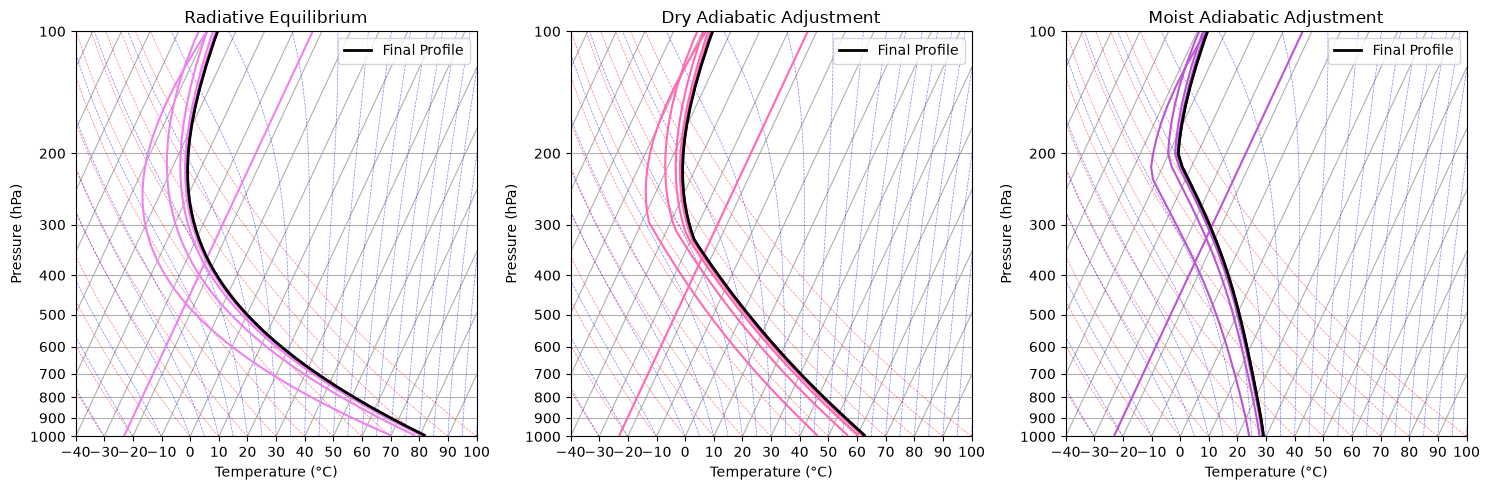

In [35]:
fig = plt.figure(figsize=(15, 5))
p = (grid['p_mid'] * units.Pa).to('hPa')

#plotting radiative equilibrium
skew1 = SkewT(fig, rotation=25, subplot=(1, 3, 1), aspect='auto')
for idx, T_data in enumerate(history_save['radiative']['T']):
    T = T_data * units.degC
    skew1.plot(p, T, color='violet')

radiative_final = history_save['radiative']['T'][-1] * units.degC 
skew1.plot(p, radiative_final, 'black', label='Final Profile', linewidth=2)

skew1.ax.set_ylim(1000, 100)
skew1.ax.set_xlim(-40, 100)
skew1.ax.set_title('Radiative Equilibrium')
skew1.ax.set_ylabel('Pressure (hPa)')
skew1.ax.set_xlabel('Temperature (°C)')
skew1.ax.legend(loc='upper right')

skew1.plot_dry_adiabats(linewidth=0.5, alpha=0.5)
skew1.plot_moist_adiabats(linewidth=0.5, alpha=0.5)

#plotting dry adiabatic adjustment
skew2 = SkewT(fig, rotation=25, subplot=(1, 3, 2), aspect='auto')
for idx, T_data in enumerate(history_save['dry']['T']):
    T = T_data * units.degC
    skew2.plot(p, T, color='hotpink')

dry_final = history_save['dry']['T'][-1] * units.degC
skew2.plot(p, dry_final, 'black', label='Final Profile', linewidth=2)

skew2.ax.set_ylim(1000, 100)
skew2.ax.set_xlim(-40, 100)
skew2.ax.set_title('Dry Adiabatic Adjustment')
skew2.ax.set_ylabel('Pressure (hPa)')
skew2.ax.set_xlabel('Temperature (°C)')
skew2.ax.legend(loc='upper right')
skew2.plot_dry_adiabats(linewidth=0.5, alpha=0.5)
skew2.plot_moist_adiabats(linewidth=0.5, alpha=0.5)

#plotting moist adiabatic adjustment
skew3 = SkewT(fig, rotation=25, subplot=(1, 3, 3), aspect='auto')
for idx, T_data in enumerate(history_save['moist']['T']):
    T = T_data * units.degC
    skew3.plot(p, T, color='mediumorchid')

moist_final = history_save['moist']['T'][-1] * units.degC
skew3.plot(p, moist_final, 'black', label='Final Profile', linewidth=2)

skew3.ax.set_ylim(1000, 100)
skew3.ax.set_xlim(-40, 100)
skew3.ax.set_title('Moist Adiabatic Adjustment')
skew3.ax.set_ylabel('Pressure (hPa)')
skew3.ax.set_xlabel('Temperature (°C)')
skew3.ax.legend(loc='upper right')
skew3.plot_dry_adiabats(linewidth=0.5, alpha=0.5)
skew3.plot_moist_adiabats(linewidth=0.5, alpha=0.5)

plt.tight_layout()
plt.show();

This 3-panel figure above was created to mimic Figure 1 in Manabe and Strickler 1964. This figure from the paper was meant to demonstrate how both the radiative and thermal temperature profiles reach equilibrium as time progresses. Their study looked at both warm and cold isothermal experiments, but ours only focused on the cold experiment. They also did not skew their isotherms like in the figure included here. Despite these two differences, the above panels correspond well to the results they plotted to show the temperature profiles reaching equilibrium. Their initial isothermal profile is displayed as the vertical, dashed line located on the left of both panels. The initial profiles for the experiments above are the linear lines following the ~ -24°C isotherm. As the experiments run, the paper profiles begin to shift right towards the final state as mine do here. Additionally, both experiments in the paper started with cold surface temperatures which then increase significantly as the model runs. In both the paper and these panels, the spatial difference between the iterations decreases as the model reaches equilibrium.

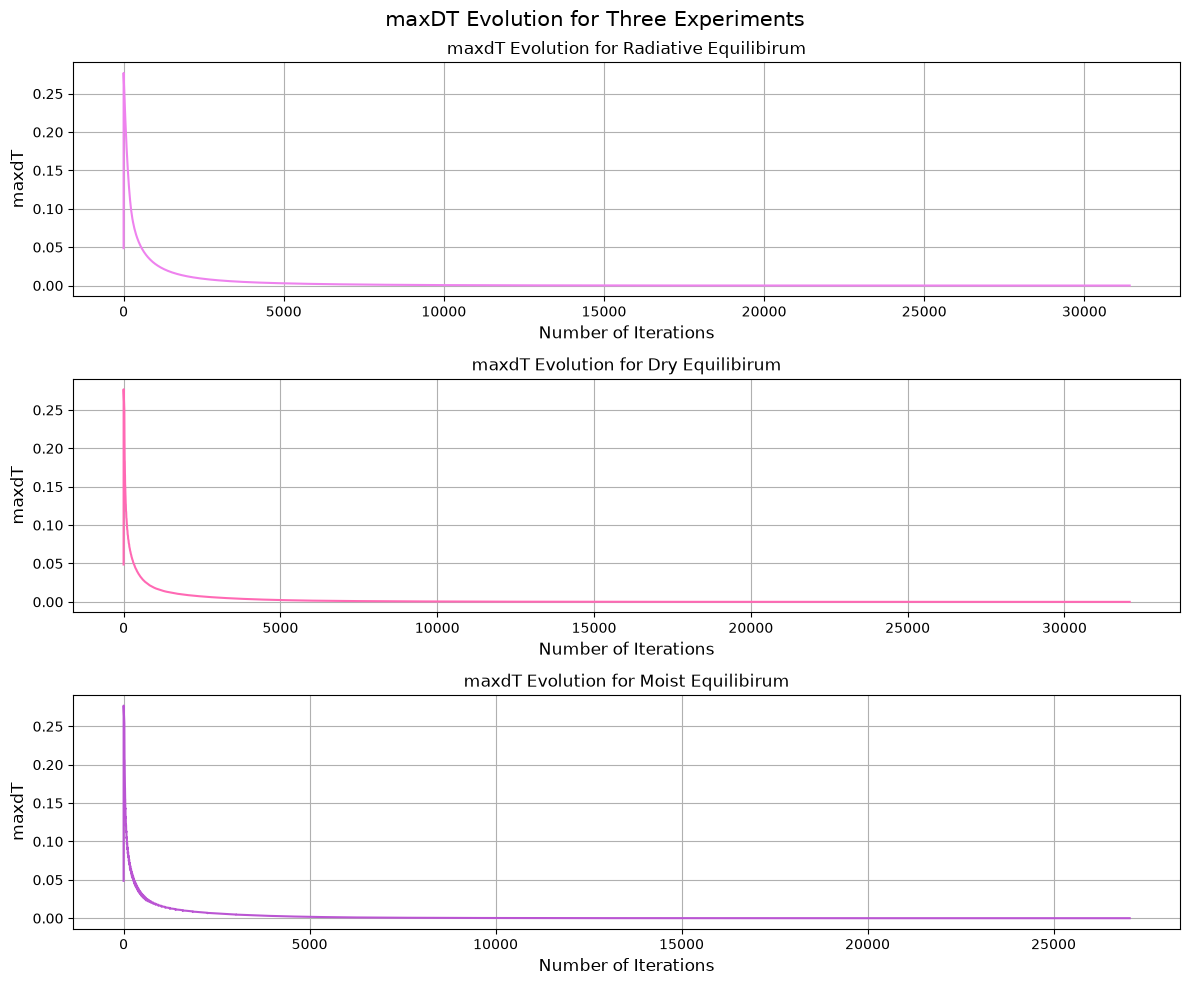

In [36]:
fig, ax = plt.subplots(3, 1, figsize=(12,10))
ax[0].grid()
ax[0].plot(history_save['radiative']['maxdT'], color='violet')
ax[0].set_ylabel('maxdT', fontsize = 12)
ax[0].set_xlabel('Number of Iterations', fontsize = 12)
ax[0].set_title('maxdT Evolution for Radiative Equilibirum')

ax[1].grid()
ax[1].plot(history_save['dry']['maxdT'], color='hotpink')
ax[1].set_ylabel('maxdT', fontsize = 12)
ax[1].set_xlabel('Number of Iterations', fontsize = 12)
ax[1].set_title('maxdT Evolution for Dry Equilibirum')

ax[2].grid()
ax[2].plot(history_save['moist']['maxdT'], color='mediumorchid')
ax[2].set_ylabel('maxdT', fontsize = 12)
ax[2].set_xlabel('Number of Iterations', fontsize = 12)
ax[2].set_title('maxdT Evolution for Moist Equilibirum')

plt.suptitle('maxDT Evolution for Three Experiments', fontsize=15)
plt.tight_layout()

The above figure was designed to show maxdT over time for all three equilibrium scenarios. The reason for this choice is that maxdT was used as the equilibrium condition in the model with a threshold value of $10^{-6}$. The idea is that we can assume model converges (reaches equilibrium) when the maximum temperature change becomes so small that the value is negligible. This approach follows Manabe and Strickler (1964)in section 2c, where the authors discuss different computational methods. Though different threshold values were chosen between this lab and the paper, the result is still the same. In all three experiments, maxdT is largest at the beginning of the experiment. As the model runs, maxdT decreases exponentially for all three cases. MaxdT asymptotically approaches zero and the model reaches convergence when maxdT is smaller than the tolerance value. Interestingly enough, each experiment reaches equilibrium after different iteration lengths. This decrease in maxdT can also be observed visually in the 3-panel skewT, where the temperature profiles in each experiment get closer to each other as the model runs.

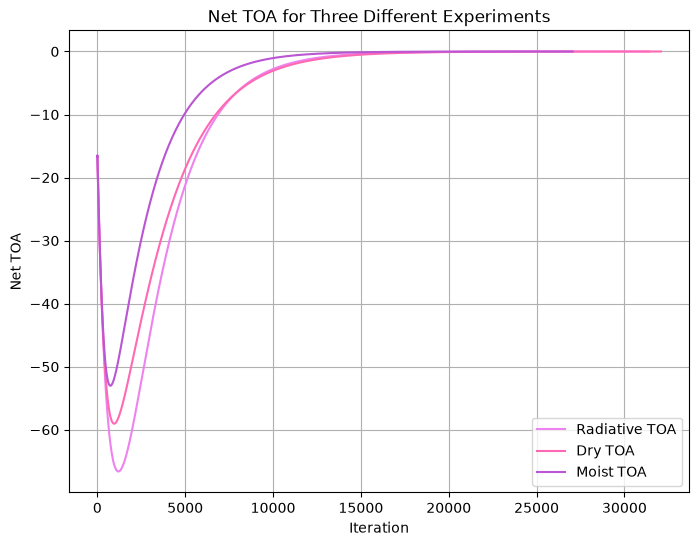

In [13]:
fig = plt.figure(figsize=(8,6))
plt.plot(history_save['radiative']['TOA_net'], label='Radiative TOA', color='violet')
plt.plot(history_save['dry']['TOA_net'], label='Dry TOA', color='hotpink')
plt.plot(history_save['moist']['TOA_net'], label='Moist TOA', color='mediumorchid')
plt.legend()
plt.xlabel('Iteration')
plt.ylabel('Net TOA')
plt.grid()
plt.title('Net TOA for Three Different Experiments');

For my third plot, I decided to plot the net radiation at the top of the atmosphere over time for all three experiments. Equilibrium is reached as the net radiation at the top of the atmosphere asymptotically reaches zero. Here, we can see that all three experiments reach equilibrium, though with different number of iterations.

#### 2. A skewT with the final equilibrium T-profiles (Teq) for all three scenarios overlaid

/Users/emmatrask/opt/anaconda3/envs/metr5003/lib/python3.14t/site-packages/metpy/plots/skewt.py:370: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r" (-> color=(1.0, 0.0, 0.0, 1)). The keyword argument will take precedence.
  return self.ax.plot(t, pressure, *args, **kwargs)
/Users/emmatrask/opt/anaconda3/envs/metr5003/lib/python3.14t/site-packages/metpy/plots/skewt.py:370: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "g" (-> color=(0.0, 0.5, 0.0, 1)). The keyword argument will take precedence.
  return self.ax.plot(t, pressure, *args, **kwargs)
/Users/emmatrask/opt/anaconda3/envs/metr5003/lib/python3.14t/site-packages/metpy/plots/skewt.py:370: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "b" (-> color=(0.0, 0.0, 1.0, 1)). The keyword argument will take precedence.
  return self.ax.plot(t, pressure, *args, **kwargs)


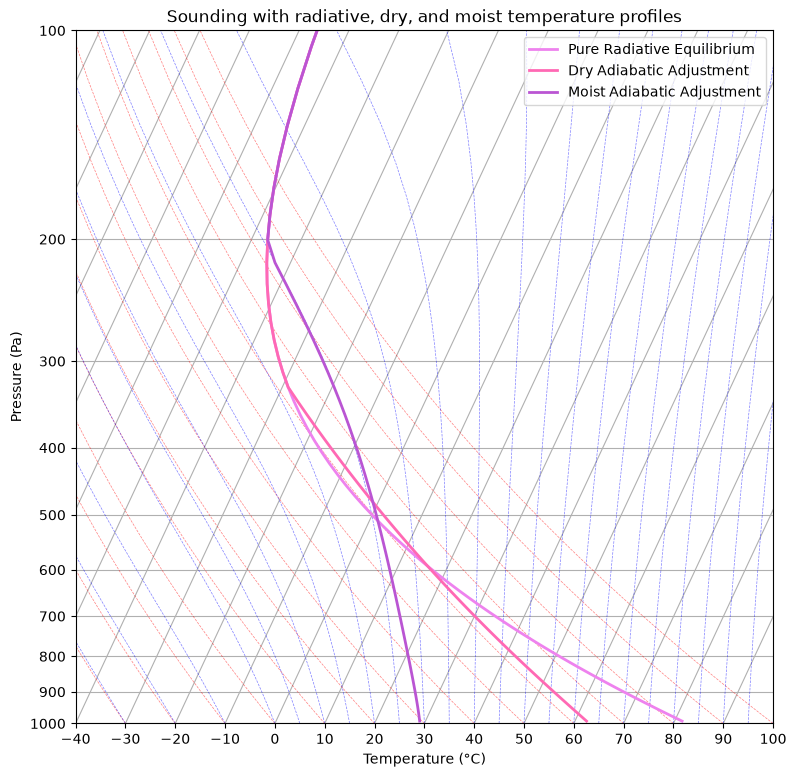

In [14]:
fig = plt.figure(figsize=(9, 9))
skew = SkewT(fig, rotation=25,aspect='auto')
p = grid['p_mid'] * units.Pa
radiative = history_save['radiative']['T'][-1] * units.degC
dry = history_save['dry']['T'][-1] * units.degC
moist = history_save['moist']['T'][-1] * units.degC


skew.plot(p, radiative, 'r', label='Pure Radiative Equilibrium', linewidth=2, color='violet')
skew.plot(p, dry, 'g', label='Dry Adiabatic Adjustment', linewidth=2, color='hotpink')
skew.plot(p, moist, 'b', label='Moist Adiabatic Adjustment', linewidth=2, color='mediumorchid')

skew.ax.set_ylim(1000, 100)
skew.ax.set_xlim(-40, 100)


skew.ax.set_xlabel(f'Temperature ({radiative.units:~P})')
skew.ax.set_ylabel(f'Pressure ({p.units:~P})')
skew.ax.set_title('Sounding with radiative, dry, and moist temperature profiles')
skew.ax.legend()

skew.plot_dry_adiabats(linewidth=0.5, alpha=0.5)
skew.plot_moist_adiabats(linewidth=0.5, alpha=0.5)


plt.show()

#### 3. A discussion of how and why the three Teq -profiles differ among the three equilibrium scenarios.

All three profiles initially start the model with the same with the same isothermal temperature profile. However, in pure radiative equilibrium, the temperature profile is absolutely unstable in a greenhouse atmospere. Looking at the skewT in 2), we can see that the environmental lapse rate ($\Gamma_e$) of the radiative profile is greater than the dry adiabatic lapse rate ($\Gamma_d$) at the surface, indicating absolute instability with a unrealistically warm surface temperature. It then becomes stable in the upper troposphere at approximately 330 mb. Earth's atmosphere is nearly transparent to incoming shortwave which is received by the surface and lower layers of the atmosphere. Because we exist in a greenhouse atmosphere, the layers above absorb some of the outgoing longwave from the surface and re-emit it downwards. Because of this process, you have to heat the atmosphere to balance the incoming radiation which produced the "bottom heavy" warm layer that is absolutely unstable. This process occuring near the surface from the outgoing longwave then promotes mixing and then drives convection to get rid of the instability. Adding dry or moist convective adjustment to this profile will assist in moving heat upwards to cool the surface which also warms the upper troposphere relative to the radiative equilibrium profile. All three profiles are the same in the upper troposphere because the radiative equilibrium profile is no longer absolutely unstable in this layer and therefore no adjustments are made.


$\Gamma_e$ of the dry adjustment temperature profile is the same as $\Gamma_d$ from the surface to approximately 330 mb when it then follows the radiative equilibrium temperature profile. When dry convective mixing is applied to the temperature profile, it neutralizes the lower troposphere by cooling it so that it follows the dry adiabatic lapse rate. As the convective mixing is applied and heat is tranferred upward, there results a layer from 600 to 330 mb where the dry profile is warmer than the radiative profile. The mixing continues until 330 mb where the radiative equilibrium temperature profile becomes stable and there is no need to adjust. $\Gamma_e$ of the moist adjustment temperature profile is less than $\Gamma_d$, but greater than the most adiabatic lapse rate ($\Gamma_m$). Therefore, this layer located from the surface to approximately 200 mb is conditionally unstable. Like the dry adjustment, the surface is cooled and the upper troposphere warms in the moist adiabatic profile. In the moist scenario, latent heat is released and offsets adiabatic cooling so the moist adiabatic lapse rate is initially very small. Then, convective mixing is stronger and more heat is transported upwards from the surface. Moreover, the surface cools to a lower temperature and this process results in the differences in surface temperature between all three profiles. Another difference between the dry and moist adiabatic profile is where the profile meets the radiative equilibrium profile. For the dry profile, this is at 330 mb. For the moist profile, this is at 200 mb. Because the moist profile is more unstable at the surface than the dry profile, the column height is higher in order to maintain energy conservation before it meets the radiative profile. Because moist convection extends higher into the troposphere, the moist profile is also warmer from 480 to 200 mb. 



#### 4. A discussion of how the approach to equilibrium differs among the three equilibrium scenarios, and the physical explanation for these differences.

Despite having the same equilibrium conditions in the model, each of the three scenarios varies in how long it takes to reach equilibrium which results from how equilibrium is reached. Equilibrium is reached when the outgoing LW is equal to incoming SW, with outgoing LW arising partly from the temperature of the highest layer of the atmosphere. Looking at the net TOA plot above, one can see that the radiative and dry profiles reach equilibrium after a greater number of iterations compared to the moist profile.  This difference is due to how heat is transported upwards in the atmosphere from a very warm surface temperature. 

In the radiative case, heat is transported upwards from the interactions of SW and LW fluxes with the greenhouse atmosphere and vertical mixing is not present. Incoming shortwave radiation intially warms the surface but because we have a greenhouse atmosphere, much of the emitted LW radiation from the surface is trapped in lower layers of the atmosphere. With much of the emitted LW radiation trapped in the lower troposphere, very little heat is transported to the upper tropsphere and outgoing LW at the top of the atmosphere is small when considering the $\sigma T^4$ term used in the calculation. This makes net TOA large and also explains why net TOA is largest for the radiative equilibrium experiment. In order for equilibrium to be reached, the outgoing LW and incoming SW must be equal. The model is then ran repeatedly until enough heat is transported upwards so that the outgoing LW and SW are equal to one another. Without the assistance of convection for upward transport, this process is much slower.

When considering moist and dry radiative equilibrium, convection is introduced alongside radiative processes to assist in warming the upper troposphere and increasing outgoing LW. Instead of waiting for just radiative processes, the convective adjustment process immediately takes in heat from the layer below while remaining energy conserving. This allows for heat to reach the upper troposphere at a quicker rate which in turn increases outgoing LW and decreases net TOA. With moist equilibrium, the criteria for adding mixing is easier to reach because the MALR is lower than the DALR, especially at high temperatures which we saw in Lab 3. As a result, convective mixing occurs earlier in the moist case than the dry case. Therefore, the moist case reaches a net TOA of 0 before the dry case from this strong vertical heat transport.

#### 5. A discussion of some of the choices you had to make in implementing new components in the model and your process and logic for making those choices.

One of the choices I made was adding "maxdT" into what was being saved in the history instead of just printing it out. Though I had a multitude of variable choices for showing equilibrium, using "maxdT" allowed me to be consistent with how I was checking for equilibrium in my model code and how Manabe and Strickler (1964) checked for equilibrium computationally. To make this change, I just added an entry to the "history" dictionary in the "save_singlelev_step" function. 

Another change I made was adding an additional thermodynamic function for the dry adiabatic lapse rate (DALR) in the "Thermodynamic functions" cell. Though $\frac{g}{c_p}$ would generally be a good assumption, this model is working in pressure coordinates and so is the moist adiabatic lapse rate which takes in DALR as an input. The equation for the DALR in pressure coordinates was taken from Grant Petty's "A First Course in Atmospheric Thermodynamics" and calculates the DALR for each temperature layer within the layer.

When initially computing the fluxes, I was hardcoding the boundary conditions for F_up and F_down outside of the loops I was working with. However, I noticed that looping through would overwrite the boundary conditions and the model would not initialize correctly. Instead, I added an additional "if" statement within the loop to place the boundary conditions at the first index, and then continue the loop for the subsequent indices. Without this change, I was getting very unphysical surface temperatures within my model runs from how I was initializing.